In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/blue/eee6778/nvasanthakumar/MotionProof-AI")
DATA_DIR = PROJECT_ROOT / "data" / "raw"
S1_PATH = DATA_DIR / "PPG_FieldStudy" / "S1" / "S1.pkl"

print("MotionProof AI — Dataset Setup")
print("=" * 45)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Dataset exists:", S1_PATH.exists())

if S1_PATH.exists():
    print("S1 file size:", round(S1_PATH.stat().st_size / (1024**3), 2), "GiB")

MotionProof AI — Dataset Setup
Python: 3.10.12
NumPy: 1.24.1
Pandas: 2.1.4
SciPy: 1.12.0
Dataset exists: True
S1 file size: 1.35 GiB


In [2]:
from pathlib import Path
import os
import resource

print("MotionProof AI — Memory Safety Check")
print("=" * 45)

# Check Linux cgroup memory limits.
cgroup_paths = [
    Path("/sys/fs/cgroup/memory.max"),
    Path("/sys/fs/cgroup/memory/memory.limit_in_bytes"),
]

limit_found = False

for path in cgroup_paths:
    if path.exists():
        value = path.read_text().strip()

        if value.isdigit():
            limit_gib = int(value) / (1024**3)

            if limit_gib < 1_000_000:
                print(f"Cgroup memory limit: {limit_gib:.2f} GiB")
                limit_found = True
                break

        elif value == "max":
            print("Cgroup memory limit: Not set at this level")

soft, hard = resource.getrlimit(resource.RLIMIT_AS)

if soft != resource.RLIM_INFINITY:
    print(f"Process virtual memory limit: {soft / (1024**3):.2f} GiB")
else:
    print("Process virtual memory limit: Not explicitly set")

print("SLURM_MEM_PER_NODE:", os.environ.get("SLURM_MEM_PER_NODE", "Not reported"))
print("SLURM_MEM_PER_CPU:", os.environ.get("SLURM_MEM_PER_CPU", "Not reported"))

if not limit_found:
    print("\nMemory allocation could not be confirmed from these checks.")
    print("Check your HiPerGator JupyterLab session's requested memory.")

MotionProof AI — Memory Safety Check
Process virtual memory limit: Not explicitly set
SLURM_MEM_PER_NODE: 16384
SLURM_MEM_PER_CPU: Not reported

Memory allocation could not be confirmed from these checks.
Check your HiPerGator JupyterLab session's requested memory.


In [3]:
import pickle
import time
import os

print("MotionProof AI — Loading Participant S1")
print("=" * 50)

# Confirm that the dataset exists
assert S1_PATH.exists(), "S1 dataset file not found!"

print(f"Dataset size: {S1_PATH.stat().st_size / (1024**3):.2f} GiB")

# Load the trusted PPG-DaLiA dataset
start_time = time.time()

with open(S1_PATH, "rb") as file:
    s1_data = pickle.load(file, encoding="latin1")

elapsed = time.time() - start_time

print(f"\nDataset loaded successfully in {elapsed:.2f} seconds")

# Inspect top-level structure
print("\nDataset type:", type(s1_data))

if isinstance(s1_data, dict):
    print("\nAvailable keys:")

    for key, value in s1_data.items():
        print(f"  {key}: {type(value).__name__}")

print("\nS1 loading complete!")

MotionProof AI — Loading Participant S1
Dataset size: 1.35 GiB

Dataset loaded successfully in 3.94 seconds

Dataset type: <class 'dict'>

Available keys:
  rpeaks: ndarray
  signal: dict
  label: ndarray
  activity: ndarray
  questionnaire: dict
  subject: str

S1 loading complete!


In [4]:
print("MotionProof AI — S1 Signal Structure")
print("=" * 55)

# Participant identifier
print("\nParticipant:", s1_data["subject"])

# Inspect signal structure
signals = s1_data["signal"]

print("\nAvailable sensor locations:")
for location in signals:
    print(" -", location)

# Inspect each sensor and its dimensions
for location, sensors in signals.items():

    print(f"\n{location.upper()} SENSORS")
    print("-" * 40)

    for sensor_name, values in sensors.items():

        print(
            f"{sensor_name:12s} "
            f"Shape: {str(values.shape):20s} "
            f"Data type: {values.dtype}"
        )

# Inspect reference labels
print("\nREFERENCE HEART RATE LABELS")
print("-" * 40)

labels = s1_data["label"]

print("Shape:", labels.shape)
print("Data type:", labels.dtype)
print("Number of labels:", len(labels))

# Inspect activity annotations
print("\nACTIVITY ANNOTATIONS")
print("-" * 40)

activities = s1_data["activity"]

print("Shape:", activities.shape)
print("Data type:", activities.dtype)
print("Unique activity codes:", np.unique(activities))

print("\nSignal inspection complete!")

MotionProof AI — S1 Signal Structure

Participant: S1

Available sensor locations:
 - chest
 - wrist

CHEST SENSORS
----------------------------------------
ACC          Shape: (6448400, 3)         Data type: float64
ECG          Shape: (6448400, 1)         Data type: float64
EMG          Shape: (6448400, 1)         Data type: float64
EDA          Shape: (6448400, 1)         Data type: float64
Temp         Shape: (6448400, 1)         Data type: float32
Resp         Shape: (6448400, 1)         Data type: float64

WRIST SENSORS
----------------------------------------
ACC          Shape: (294784, 3)          Data type: float64
BVP          Shape: (589568, 1)          Data type: float64
EDA          Shape: (36848, 1)           Data type: float64
TEMP         Shape: (36848, 1)           Data type: float64

REFERENCE HEART RATE LABELS
----------------------------------------
Shape: (4603,)
Data type: float64
Number of labels: 4603

ACTIVITY ANNOTATIONS
--------------------------------------

MotionProof AI — Physiological Signal Visualization


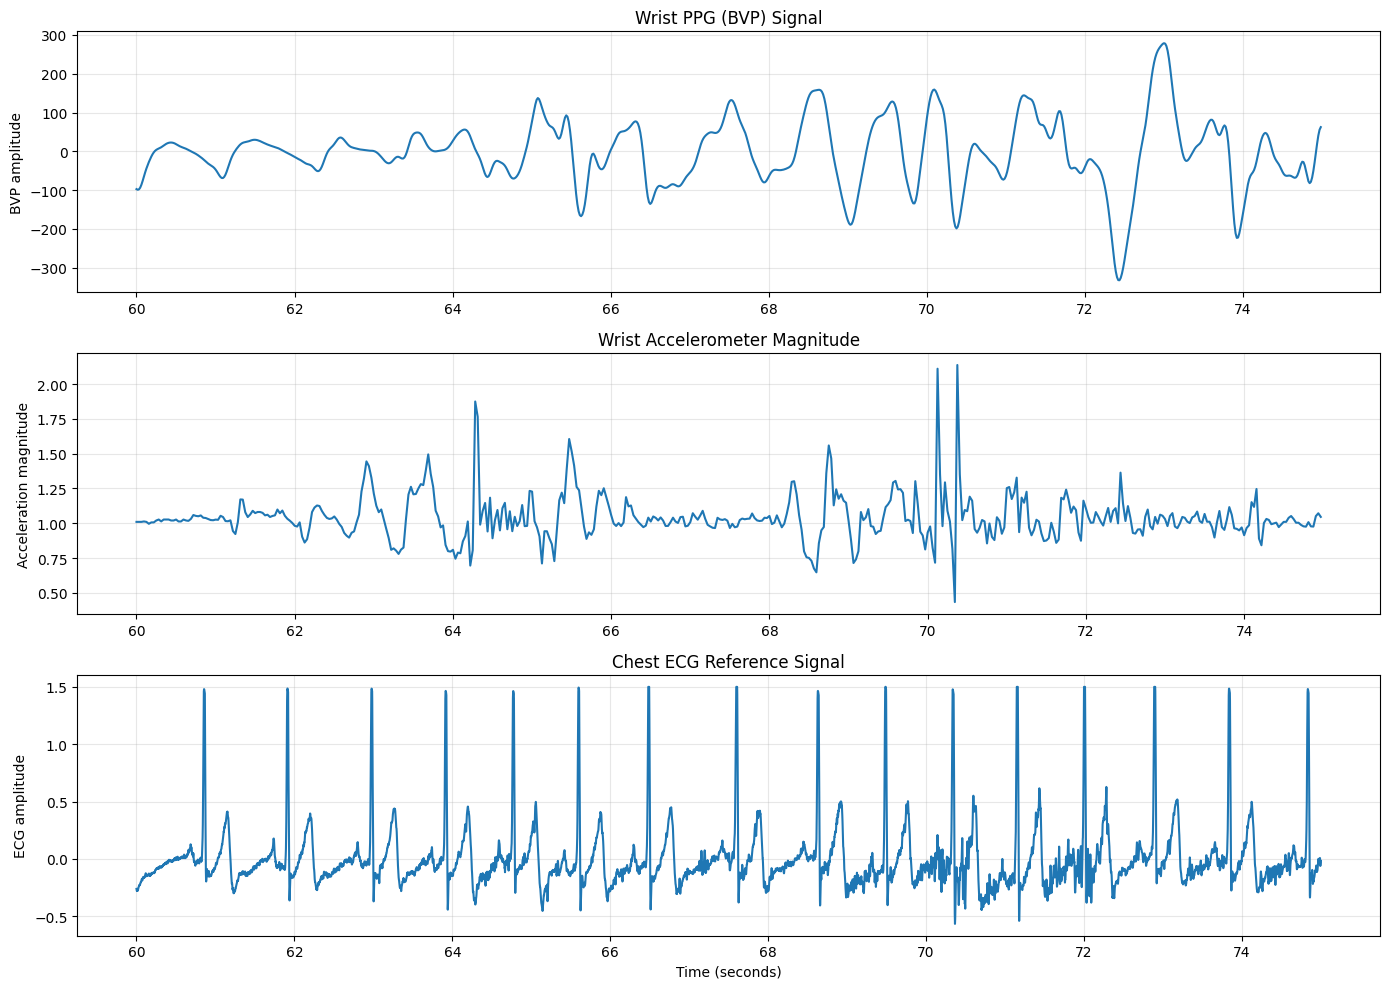


Visualization saved to:
/blue/eee6778/nvasanthakumar/MotionProof-AI/results/plots/S1_signal_visualization.png

Segment statistics:
PPG samples: 960
ACC samples: 480
ECG samples: 10500


In [5]:
import numpy as np
import matplotlib.pyplot as plt

print("MotionProof AI — Physiological Signal Visualization")
print("=" * 55)

# Sampling frequencies
FS_PPG = 64
FS_ACC = 32
FS_ECG = 700

# Extract signals
ppg = s1_data["signal"]["wrist"]["BVP"][:, 0]
acc = s1_data["signal"]["wrist"]["ACC"]
ecg = s1_data["signal"]["chest"]["ECG"][:, 0]

# Choose a short segment
start_seconds = 60
duration_seconds = 15

# Calculate sample indices
ppg_start = int(start_seconds * FS_PPG)
ppg_end = int((start_seconds + duration_seconds) * FS_PPG)

acc_start = int(start_seconds * FS_ACC)
acc_end = int((start_seconds + duration_seconds) * FS_ACC)

ecg_start = int(start_seconds * FS_ECG)
ecg_end = int((start_seconds + duration_seconds) * FS_ECG)

# Extract only the selected segment
ppg_segment = ppg[ppg_start:ppg_end]
acc_segment = acc[acc_start:acc_end]
ecg_segment = ecg[ecg_start:ecg_end]

# Generate time axes
t_ppg = np.arange(len(ppg_segment)) / FS_PPG + start_seconds
t_acc = np.arange(len(acc_segment)) / FS_ACC + start_seconds
t_ecg = np.arange(len(ecg_segment)) / FS_ECG + start_seconds

# Calculate accelerometer magnitude
acc_magnitude = np.linalg.norm(acc_segment, axis=1)

# Create plots
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# PPG signal
axes[0].plot(t_ppg, ppg_segment)
axes[0].set_title("Wrist PPG (BVP) Signal")
axes[0].set_ylabel("BVP amplitude")
axes[0].grid(True, alpha=0.3)

# Accelerometer magnitude
axes[1].plot(t_acc, acc_magnitude)
axes[1].set_title("Wrist Accelerometer Magnitude")
axes[1].set_ylabel("Acceleration magnitude")
axes[1].grid(True, alpha=0.3)

# ECG reference
axes[2].plot(t_ecg, ecg_segment)
axes[2].set_title("Chest ECG Reference Signal")
axes[2].set_ylabel("ECG amplitude")
axes[2].set_xlabel("Time (seconds)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()

# Save visualization
output_dir = PROJECT_ROOT / "results" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "S1_signal_visualization.png"

plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("\nVisualization saved to:")
print(output_path)

print("\nSegment statistics:")
print("PPG samples:", len(ppg_segment))
print("ACC samples:", len(acc_segment))
print("ECG samples:", len(ecg_segment))

MotionProof AI — Heart Rate Reference Analysis

RECORDING DURATIONS
PPG duration: 9212.00 seconds
ACC duration: 9212.00 seconds
ECG duration: 9212.00 seconds

HEART RATE LABELS
Number of labels: 4603
Minimum HR: 41.86 BPM
Maximum HR: 150.15 BPM
Mean HR: 74.84 BPM
Median HR: 71.76 BPM
Standard deviation: 16.16

LABEL TIMING
Nominal label stride: 2 seconds
Recording duration: 9212.0 seconds
Number of labels: 4603
Approximate duration covered by label strides: 9206 seconds


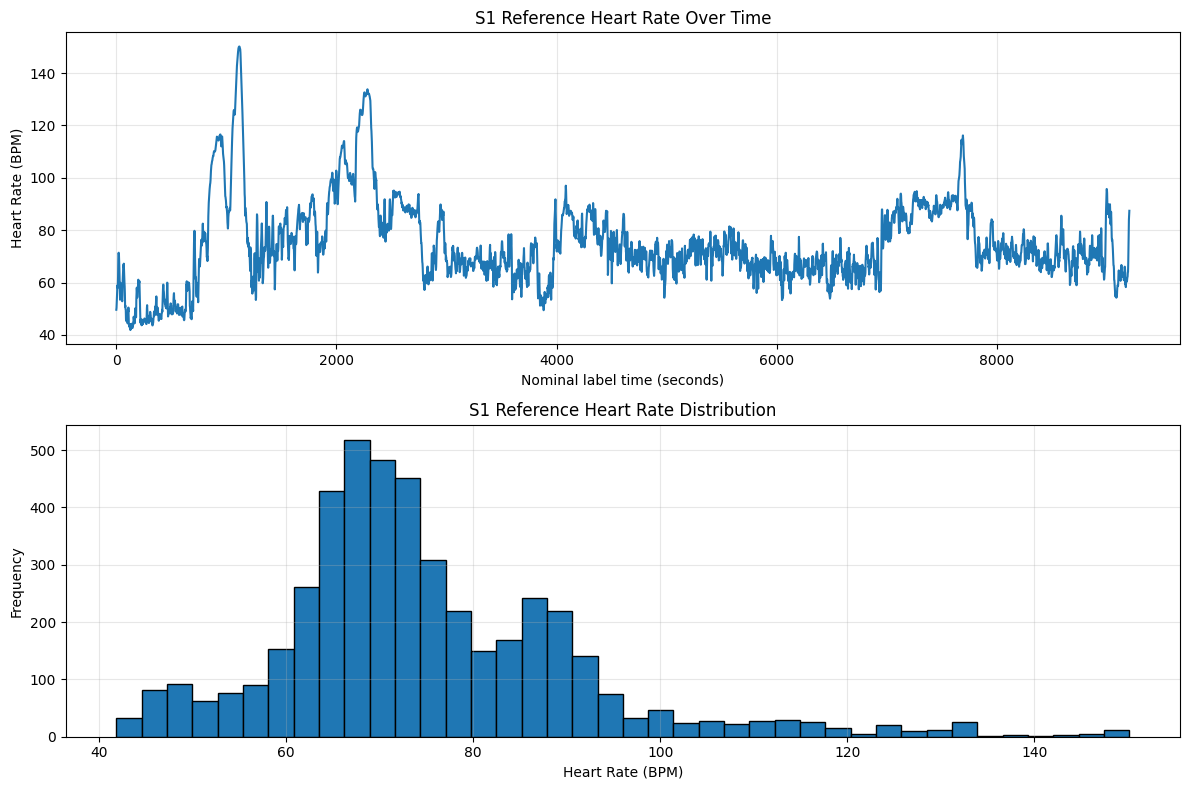


Saved visualization:
/blue/eee6778/nvasanthakumar/MotionProof-AI/results/plots/S1_reference_heart_rate.png


In [6]:
print("MotionProof AI — Heart Rate Reference Analysis")
print("=" * 55)

# Extract reference labels
hr_labels = np.asarray(s1_data["label"]).reshape(-1)

# Calculate recording duration
ppg_duration = len(ppg) / FS_PPG
acc_duration = len(acc) / FS_ACC
ecg_duration = len(ecg) / FS_ECG

print("\nRECORDING DURATIONS")
print(f"PPG duration: {ppg_duration:.2f} seconds")
print(f"ACC duration: {acc_duration:.2f} seconds")
print(f"ECG duration: {ecg_duration:.2f} seconds")

print("\nHEART RATE LABELS")
print("Number of labels:", len(hr_labels))
print("Minimum HR:", round(np.min(hr_labels), 2), "BPM")
print("Maximum HR:", round(np.max(hr_labels), 2), "BPM")
print("Mean HR:", round(np.mean(hr_labels), 2), "BPM")
print("Median HR:", round(np.median(hr_labels), 2), "BPM")
print("Standard deviation:", round(np.std(hr_labels), 2))

# PPG-DaLiA reference labels are supplied at a nominal 2-second stride.
LABEL_STRIDE_SECONDS = 2

print("\nLABEL TIMING")
print("Nominal label stride:", LABEL_STRIDE_SECONDS, "seconds")
print("Recording duration:", round(ppg_duration, 2), "seconds")
print("Number of labels:", len(hr_labels))
print(
    "Approximate duration covered by label strides:",
    len(hr_labels) * LABEL_STRIDE_SECONDS,
    "seconds"
)

# Visualize the reference heart-rate distribution
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(
    np.arange(len(hr_labels)) * LABEL_STRIDE_SECONDS,
    hr_labels
)
axes[0].set_title("S1 Reference Heart Rate Over Time")
axes[0].set_xlabel("Nominal label time (seconds)")
axes[0].set_ylabel("Heart Rate (BPM)")
axes[0].grid(True, alpha=0.3)

axes[1].hist(hr_labels, bins=40, edgecolor="black")
axes[1].set_title("S1 Reference Heart Rate Distribution")
axes[1].set_xlabel("Heart Rate (BPM)")
axes[1].set_ylabel("Frequency")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

output_path = output_dir / "S1_reference_heart_rate.png"
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("\nSaved visualization:")
print(output_path)

In [7]:
print("MotionProof AI — Reference Window Alignment")
print("=" * 55)

WINDOW_SECONDS = 8
STRIDE_SECONDS = 2

# Expected number of complete windows
expected_windows = (
    int((ppg_duration - WINDOW_SECONDS) // STRIDE_SECONDS) + 1
)

print("Recording duration:", ppg_duration, "seconds")
print("Window length:", WINDOW_SECONDS, "seconds")
print("Window stride:", STRIDE_SECONDS, "seconds")
print("Expected windows:", expected_windows)
print("Actual HR labels:", len(hr_labels))

assert expected_windows == len(hr_labels), (
    "Reference label count does not match expected window alignment."
)

# Inspect representative window positions
indices = [0, 1, 2, len(hr_labels) - 1]

print("\nREFERENCE WINDOW EXAMPLES")
print("-" * 55)

for i in indices:
    start = i * STRIDE_SECONDS
    end = start + WINDOW_SECONDS

    ppg_start_idx = int(start * FS_PPG)
    ppg_end_idx = int(end * FS_PPG)

    acc_start_idx = int(start * FS_ACC)
    acc_end_idx = int(end * FS_ACC)

    print(f"\nWindow {i}")
    print(f"Time: {start:.0f}–{end:.0f} seconds")
    print(f"PPG samples: {ppg_end_idx - ppg_start_idx}")
    print(f"ACC samples: {acc_end_idx - acc_start_idx}")
    print(f"Reference HR: {hr_labels[i]:.2f} BPM")

print("\nAll reference windows are consistent with the assumed alignment.")

MotionProof AI — Reference Window Alignment
Recording duration: 9212.0 seconds
Window length: 8 seconds
Window stride: 2 seconds
Expected windows: 4603
Actual HR labels: 4603

REFERENCE WINDOW EXAMPLES
-------------------------------------------------------

Window 0
Time: 0–8 seconds
PPG samples: 512
ACC samples: 256
Reference HR: 49.61 BPM

Window 1
Time: 2–10 seconds
PPG samples: 512
ACC samples: 256
Reference HR: 50.32 BPM

Window 2
Time: 4–12 seconds
PPG samples: 512
ACC samples: 256
Reference HR: 52.71 BPM

Window 4602
Time: 9204–9212 seconds
PPG samples: 512
ACC samples: 256
Reference HR: 87.41 BPM

All reference windows are consistent with the assumed alignment.


In [8]:
import numpy as np
from scipy.signal import butter, sosfiltfilt, welch

print("MotionProof AI — Signal Processing Baseline")
print("=" * 55)

# Heart rate range: 40 to 180 BPM
LOW_HZ = 40 / 60
HIGH_HZ = 180 / 60

# Create the filter once
sos = butter(
    3,
    [LOW_HZ, HIGH_HZ],
    btype="bandpass",
    fs=FS_PPG,
    output="sos"
)

def estimate_hr_from_ppg(ppg_window):
    """
    Estimate heart rate from an 8-second PPG window.
    """

    signal = np.asarray(ppg_window, dtype=np.float64).reshape(-1)

    # Check for invalid signals
    if len(signal) != 8 * FS_PPG:
        return np.nan

    if not np.all(np.isfinite(signal)):
        return np.nan

    if np.std(signal) < 1e-8:
        return np.nan

    # Remove average signal value
    signal = signal - np.mean(signal)

    # Apply bandpass filter
    filtered = sosfiltfilt(sos, signal)

    # Find dominant frequency
    frequencies, power = welch(
        filtered,
        fs=FS_PPG,
        nperseg=len(filtered),
        nfft=4096
    )

    # Consider only plausible heart-rate frequencies
    valid = (frequencies >= LOW_HZ) & (frequencies <= HIGH_HZ)

    if not np.any(valid):
        return np.nan

    dominant_frequency = frequencies[valid][
        np.argmax(power[valid])
    ]

    # Convert Hz to BPM
    predicted_hr = dominant_frequency * 60

    return float(predicted_hr)


# Test the first window
first_window = ppg[:512]

predicted_hr = estimate_hr_from_ppg(first_window)
reference_hr = hr_labels[0]

print(f"Predicted heart rate: {predicted_hr:.2f} BPM")
print(f"Reference heart rate: {reference_hr:.2f} BPM")
print(f"Absolute error: {abs(predicted_hr - reference_hr):.2f} BPM")

MotionProof AI — Signal Processing Baseline
Predicted heart rate: 44.06 BPM
Reference heart rate: 49.61 BPM
Absolute error: 5.55 BPM


In [9]:
import numpy as np
import pandas as pd
import time

print("MotionProof AI — S1 Baseline Evaluation")
print("=" * 55)

start_time = time.time()

WINDOW_SAMPLES = 8 * FS_PPG
STRIDE_SAMPLES = 2 * FS_PPG

predictions = []
references = []

# Evaluate all 4,603 windows
for i in range(len(hr_labels)):

    start_idx = i * STRIDE_SAMPLES
    end_idx = start_idx + WINDOW_SAMPLES

    ppg_window = ppg[start_idx:end_idx]

    predicted_hr = estimate_hr_from_ppg(ppg_window)

    predictions.append(predicted_hr)
    references.append(hr_labels[i])

predictions = np.asarray(predictions, dtype=float)
references = np.asarray(references, dtype=float)

# Identify valid predictions and references
valid = np.isfinite(predictions) & np.isfinite(references)

n_total = len(references)
n_valid = int(valid.sum())

coverage = 100 * n_valid / n_total

if n_valid == 0:
    raise RuntimeError("No valid predictions were generated.")

# Calculate errors only for valid predictions
absolute_errors = np.abs(predictions[valid] - references[valid])

mae = np.mean(absolute_errors)
rmse = np.sqrt(np.mean((predictions[valid] - references[valid]) ** 2))
error_over_10 = 100 * np.mean(absolute_errors > 10)

elapsed = time.time() - start_time

print(f"\nTotal windows: {n_total}")
print(f"Valid predictions: {n_valid}")
print(f"Coverage: {coverage:.2f}%")

print("\nBASELINE PERFORMANCE")
print("-" * 40)
print(f"MAE: {mae:.2f} BPM")
print(f"RMSE: {rmse:.2f} BPM")
print(f"Error >10 BPM: {error_over_10:.2f}%")
print(f"Evaluation time: {elapsed:.2f} seconds")

# Save individual predictions for later analysis
results_df = pd.DataFrame({
    "subject": "S1",
    "window_index": np.arange(n_total),
    "window_start_seconds": np.arange(n_total) * 2,
    "reference_hr": references,
    "predicted_hr": predictions,
    "valid_prediction": valid,
    "absolute_error": np.where(
        valid,
        np.abs(predictions - references),
        np.nan
    )
})

results_path = PROJECT_ROOT / "results" / "metrics"
results_path.mkdir(parents=True, exist_ok=True)

csv_path = results_path / "S1_signal_processing_predictions.csv"
results_df.to_csv(csv_path, index=False)

print("\nPredictions saved to:")
print(csv_path)

# Show first 10 predictions
display(results_df.head(10))

MotionProof AI — S1 Baseline Evaluation

Total windows: 4603
Valid predictions: 4603
Coverage: 100.00%

BASELINE PERFORMANCE
----------------------------------------
MAE: 10.15 BPM
RMSE: 16.56 BPM
Error >10 BPM: 32.61%
Evaluation time: 1.33 seconds

Predictions saved to:
/blue/eee6778/nvasanthakumar/MotionProof-AI/results/metrics/S1_signal_processing_predictions.csv


,subject,window_index,window_start_seconds,reference_hr,predicted_hr,valid_prediction,absolute_error
0,S1,0,0,49.611369,44.0625,True,5.548869
1,S1,1,2,50.323992,46.8750,True,3.448992
2,S1,2,4,52.708336,53.4375,True,0.729164
3,S1,3,6,55.640794,52.5000,True,3.140794
4,S1,4,8,57.658406,52.5000,True,5.158406
5,S1,5,10,58.911550,52.5000,True,6.411550
6,S1,6,12,57.976459,45.0000,True,12.976459
7,S1,7,14,58.676292,48.7500,True,9.926292
8,S1,8,16,62.350800,53.4375,True,8.913300
9,S1,9,18,69.113975,56.2500,True,12.863975


MotionProof AI — Baseline Error Visualization


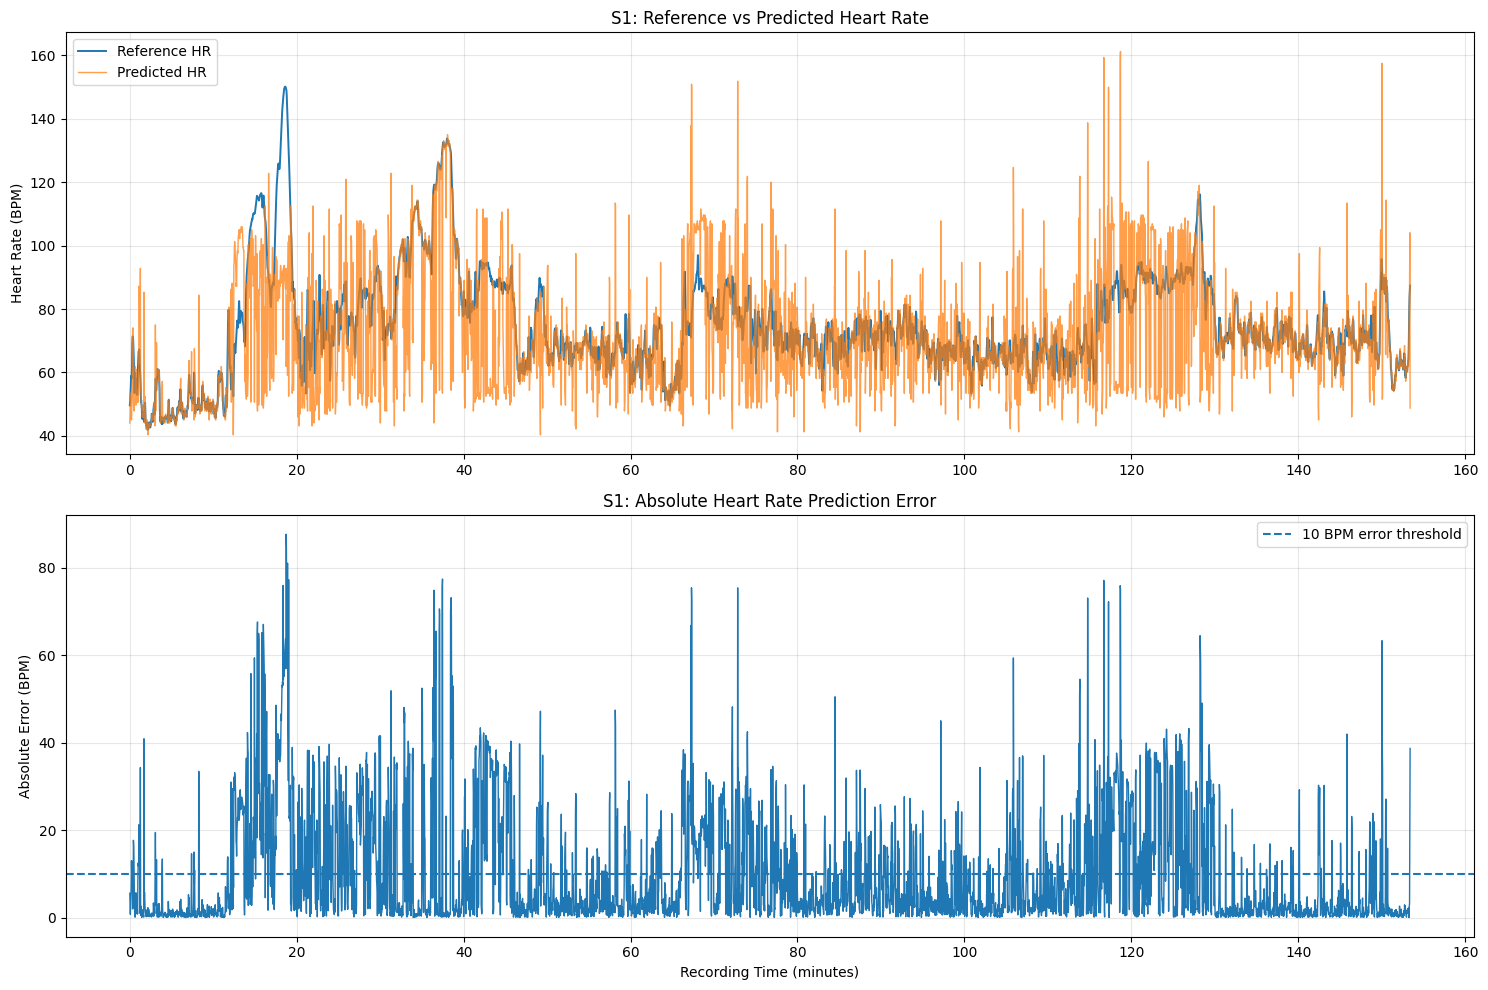


Visualization saved to:
/blue/eee6778/nvasanthakumar/MotionProof-AI/results/plots/S1_baseline_error_analysis.png

TOP 10 LARGEST PREDICTION ERRORS


,window_index,window_start_seconds,reference_hr,predicted_hr,absolute_error
562,562,1124,149.510157,61.8750,87.635157
563,563,1126,149.038054,64.6875,84.350554
567,567,1134,140.086745,59.0625,81.024245
1124,1124,2248,130.826770,53.4375,77.389270
571,571,1142,129.746323,52.5000,77.246323
3501,3501,7002,82.286454,159.3750,77.088546
551,551,1102,146.238989,70.3125,75.926489
3560,3560,7120,82.579621,158.4375,75.857879
2019,2019,4038,75.546683,150.9375,75.390817
1123,1123,2246,129.744114,54.3750,75.369114


In [10]:
import matplotlib.pyplot as plt
import numpy as np

print("MotionProof AI — Baseline Error Visualization")
print("=" * 55)

# Time axis in minutes
time_minutes = results_df["window_start_seconds"].to_numpy() / 60

reference = results_df["reference_hr"].to_numpy()
prediction = results_df["predicted_hr"].to_numpy()
errors = results_df["absolute_error"].to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Plot 1: Reference vs predicted heart rate
axes[0].plot(
    time_minutes,
    reference,
    label="Reference HR",
    linewidth=1.4
)

axes[0].plot(
    time_minutes,
    prediction,
    label="Predicted HR",
    linewidth=1,
    alpha=0.75
)

axes[0].set_title("S1: Reference vs Predicted Heart Rate")
axes[0].set_ylabel("Heart Rate (BPM)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Absolute error
axes[1].plot(
    time_minutes,
    errors,
    linewidth=1
)

axes[1].axhline(
    10,
    linestyle="--",
    label="10 BPM error threshold"
)

axes[1].set_title("S1: Absolute Heart Rate Prediction Error")
axes[1].set_xlabel("Recording Time (minutes)")
axes[1].set_ylabel("Absolute Error (BPM)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

# Save visualization
plot_path = output_dir / "S1_baseline_error_analysis.png"

plt.savefig(
    plot_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nVisualization saved to:")
print(plot_path)

# Identify the largest errors
worst_predictions = results_df.nlargest(
    10,
    "absolute_error"
)

print("\nTOP 10 LARGEST PREDICTION ERRORS")
display(
    worst_predictions[
        [
            "window_index",
            "window_start_seconds",
            "reference_hr",
            "predicted_hr",
            "absolute_error"
        ]
    ]
)

MotionProof AI — Motion vs Prediction Error
Valid windows: 4603
Spearman correlation: 0.4965

ERROR BY MOTION LEVEL


,windows,mean_absolute_error,median_absolute_error,error_over_10_percent
motion_group,,,,
Low,1535,3.10,1.56,6.84
Medium,1534,10.83,4.76,34.29
High,1534,16.52,13.80,56.71


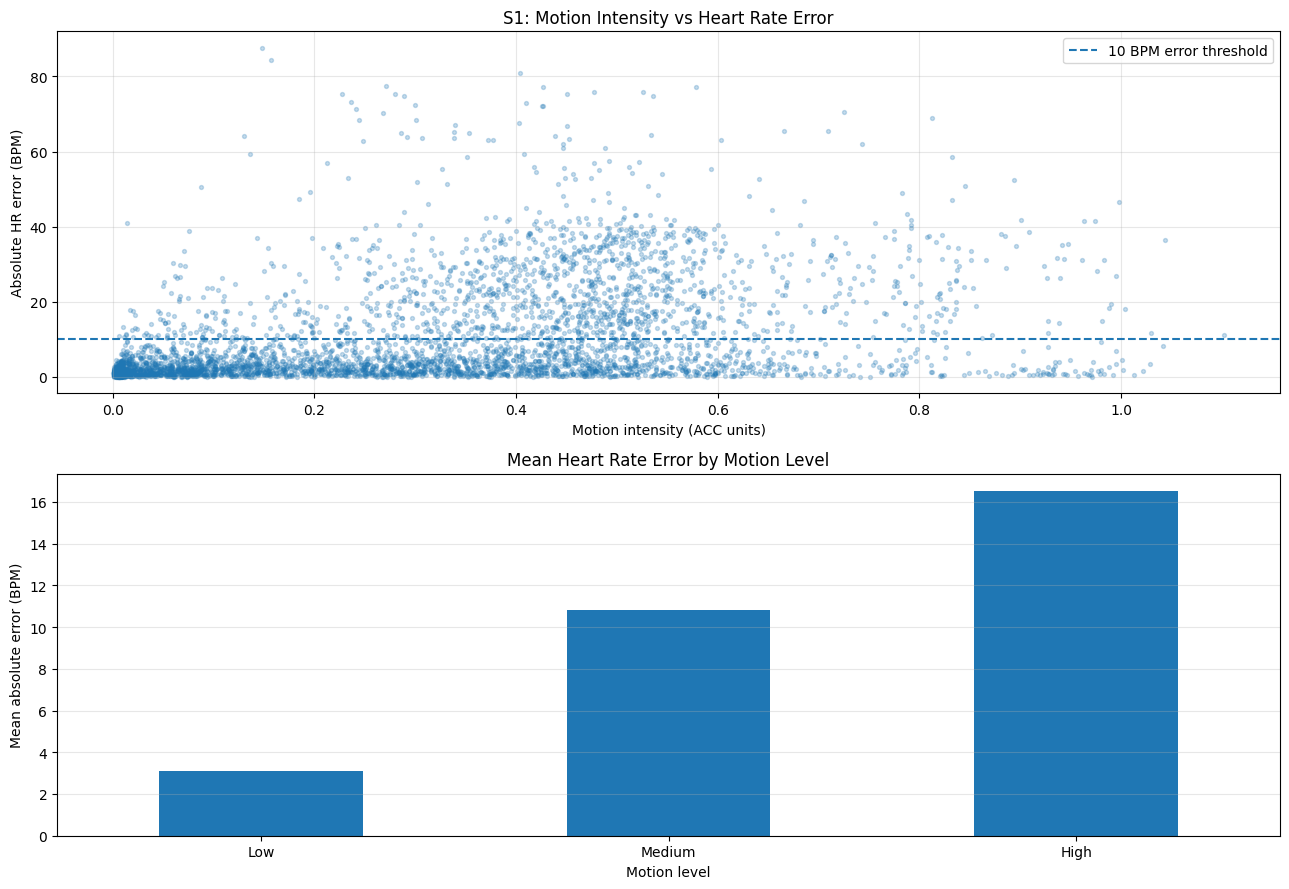


Saved plot: /blue/eee6778/nvasanthakumar/MotionProof-AI/results/plots/S1_motion_vs_error.png
Saved analysis: /blue/eee6778/nvasanthakumar/MotionProof-AI/results/metrics/S1_motion_error_analysis.csv


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("MotionProof AI — Motion vs Prediction Error")
print("=" * 55)

ACC_WINDOW_SAMPLES = 8 * FS_ACC
ACC_STRIDE_SAMPLES = 2 * FS_ACC

motion_intensities = []

for i in range(len(hr_labels)):

    start_idx = i * ACC_STRIDE_SAMPLES
    end_idx = start_idx + ACC_WINDOW_SAMPLES

    acc_window = acc[start_idx:end_idx]

    if len(acc_window) != ACC_WINDOW_SAMPLES:
        motion_intensities.append(np.nan)
        continue

    if not np.all(np.isfinite(acc_window)):
        motion_intensities.append(np.nan)
        continue

    # Remove each axis's average to reduce static gravity effects.
    centered_acc = acc_window - np.mean(
        acc_window,
        axis=0,
        keepdims=True
    )

    # RMS of dynamic acceleration across all three axes.
    motion_intensity = np.sqrt(
        np.mean(np.sum(centered_acc ** 2, axis=1))
    )

    motion_intensities.append(float(motion_intensity))

motion_intensities = np.asarray(motion_intensities)

# Add movement information to our existing results.
results_df["motion_intensity"] = motion_intensities

valid_motion = (
    np.isfinite(results_df["motion_intensity"])
    & np.isfinite(results_df["absolute_error"])
)

analysis_df = results_df.loc[valid_motion].copy()

if len(analysis_df) < 3:
    raise RuntimeError("Not enough valid windows for motion analysis.")

# Correlation between movement intensity and absolute HR error.
correlation = analysis_df[
    ["motion_intensity", "absolute_error"]
].corr(method="spearman").iloc[0, 1]

print(f"Valid windows: {len(analysis_df)}")
print(f"Spearman correlation: {correlation:.4f}")

# Divide windows into low, medium and high motion groups.
analysis_df["motion_group"] = pd.qcut(
    analysis_df["motion_intensity"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

group_summary = analysis_df.groupby(
    "motion_group",
    observed=True
).agg(
    windows=("absolute_error", "size"),
    mean_absolute_error=("absolute_error", "mean"),
    median_absolute_error=("absolute_error", "median"),
    error_over_10_percent=(
        "absolute_error",
        lambda x: 100 * np.mean(x > 10)
    )
)

print("\nERROR BY MOTION LEVEL")
display(group_summary.round(2))

# Plot movement intensity against prediction error.
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

axes[0].scatter(
    analysis_df["motion_intensity"],
    analysis_df["absolute_error"],
    s=8,
    alpha=0.25
)

axes[0].axhline(
    10,
    linestyle="--",
    label="10 BPM error threshold"
)

axes[0].set_title("S1: Motion Intensity vs Heart Rate Error")
axes[0].set_xlabel("Motion intensity (ACC units)")
axes[0].set_ylabel("Absolute HR error (BPM)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

group_summary["mean_absolute_error"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Mean Heart Rate Error by Motion Level")
axes[1].set_xlabel("Motion level")
axes[1].set_ylabel("Mean absolute error (BPM)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()

plot_path = output_dir / "S1_motion_vs_error.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

# Save updated analysis.
csv_path = results_path / "S1_motion_error_analysis.csv"
results_df.to_csv(csv_path, index=False)

print("\nSaved plot:", plot_path)
print("Saved analysis:", csv_path)

In [12]:
from scipy.signal import welch
import numpy as np

print("MotionProof AI — Motion Cadence Analysis")
print("=" * 55)

CADENCE_MIN_HZ = 0.7
CADENCE_MAX_HZ = 3.0

def estimate_motion_cadence(acc_window, fs=32):
    """
    Estimate the dominant repetitive wrist-motion frequency.

    Output is cycles per minute, which may differ from step cadence.
    """

    values = np.asarray(acc_window, dtype=np.float64)

    if values.shape != (8 * fs, 3):
        return np.nan

    if not np.all(np.isfinite(values)):
        return np.nan

    centered = values - np.mean(values, axis=0, keepdims=True)

    total_power = None

    for axis in range(3):
        frequencies, power = welch(
            centered[:, axis],
            fs=fs,
            nperseg=len(centered),
            nfft=2048
        )

        if total_power is None:
            total_power = np.zeros_like(power)

        total_power += power

    valid = (
        (frequencies >= CADENCE_MIN_HZ)
        & (frequencies <= CADENCE_MAX_HZ)
    )

    if not np.any(valid):
        return np.nan

    selected_power = total_power[valid]

    if np.max(selected_power) <= 1e-12:
        return np.nan

    dominant_frequency = frequencies[valid][
        np.argmax(selected_power)
    ]

    return float(dominant_frequency * 60)


# Estimate cadence for all 4,603 windows.
cadence_values = []

for i in range(len(hr_labels)):
    start = i * ACC_STRIDE_SAMPLES
    end = start + ACC_WINDOW_SAMPLES

    cadence = estimate_motion_cadence(acc[start:end])
    cadence_values.append(cadence)

results_df["motion_cadence_cpm"] = cadence_values

# Compare predicted HR with movement frequency.
results_df["prediction_cadence_gap"] = np.abs(
    results_df["predicted_hr"]
    - results_df["motion_cadence_cpm"]
)

results_df["reference_cadence_gap"] = np.abs(
    results_df["reference_hr"]
    - results_df["motion_cadence_cpm"]
)

# Identify possible cadence-locking patterns.
valid_cadence = (
    np.isfinite(results_df["motion_cadence_cpm"])
    & np.isfinite(results_df["predicted_hr"])
    & np.isfinite(results_df["reference_hr"])
)

candidate_locking = (
    valid_cadence
    & (results_df["prediction_cadence_gap"] <= 10)
    & (results_df["absolute_error"] > 10)
)

results_df["candidate_cadence_locking"] = candidate_locking

print("Total windows:", len(results_df))
print("Valid cadence estimates:", int(valid_cadence.sum()))
print("Candidate cadence-locking windows:", int(candidate_locking.sum()))
print(
    "Candidate percentage:",
    f"{100 * candidate_locking.mean():.2f}%"
)

print("\nFIRST 10 CANDIDATE WINDOWS")

display(
    results_df.loc[
        candidate_locking,
        [
            "window_index",
            "reference_hr",
            "predicted_hr",
            "motion_cadence_cpm",
            "absolute_error",
            "motion_intensity"
        ]
    ].head(10)
)

# Save the results.
csv_path = results_path / "S1_cadence_analysis.csv"
results_df.to_csv(csv_path, index=False)

print("\nSaved analysis:")
print(csv_path)

MotionProof AI — Motion Cadence Analysis
Total windows: 4603
Valid cadence estimates: 4602
Candidate cadence-locking windows: 611
Candidate percentage: 13.27%

FIRST 10 CANDIDATE WINDOWS


,window_index,reference_hr,predicted_hr,motion_cadence_cpm,absolute_error,motion_intensity
9,9,69.113975,56.2500,55.3125,12.863975,0.390533
30,30,63.030323,50.6250,45.0000,12.405323,0.390881
31,31,65.223567,53.4375,49.6875,11.786067,0.425139
93,93,58.029498,47.8125,42.1875,10.216998,0.495900
231,231,59.978547,45.0000,42.1875,14.978547,0.249222
351,351,63.748136,50.6250,42.1875,13.123136,0.440976
353,353,75.316807,61.8750,68.4375,13.441807,0.196980
368,368,58.636539,88.1250,90.0000,29.488461,0.169973
374,374,61.662115,93.7500,94.6875,32.087885,0.274518
375,375,65.573158,94.6875,100.3125,29.114342,0.325394



Saved analysis:
/blue/eee6778/nvasanthakumar/MotionProof-AI/results/metrics/S1_cadence_analysis.csv


In [13]:
from scipy.signal import welch
import numpy as np
import pandas as pd

print("MotionProof AI — Reliability Feature Extraction")
print("=" * 55)

def extract_ppg_quality_features(ppg_window, fs=64):
    """
    Extract simple frequency-based PPG quality indicators.

    These are exploratory features, not validated clinical
    signal-quality scores.
    """

    signal = np.asarray(ppg_window, dtype=np.float64).reshape(-1)

    if len(signal) != 8 * fs or not np.all(np.isfinite(signal)):
        return np.nan, np.nan

    signal = signal - np.mean(signal)

    if np.std(signal) < 1e-8:
        return np.nan, np.nan

    filtered = sosfiltfilt(sos, signal)

    frequencies, power = welch(
        filtered,
        fs=fs,
        nperseg=len(filtered),
        nfft=4096
    )

    valid = (frequencies >= LOW_HZ) & (frequencies <= HIGH_HZ)
    selected_power = power[valid]

    total_power = selected_power.sum()

    if total_power <= 1e-12:
        return np.nan, np.nan

    normalized_power = selected_power / total_power

    # Spectral concentration: proportion of power near
    # the dominant frequency.
    peak_index = int(np.argmax(selected_power))
    left = max(0, peak_index - 3)
    right = min(len(selected_power), peak_index + 4)

    spectral_concentration = (
        selected_power[left:right].sum() / total_power
    )

    # Normalized spectral entropy
    entropy = -np.sum(
        normalized_power * np.log(normalized_power + 1e-12)
    )

    spectral_entropy = entropy / np.log(len(normalized_power))

    return float(spectral_concentration), float(spectral_entropy)


quality_values = []
entropy_values = []

for i in range(len(hr_labels)):
    start = i * STRIDE_SAMPLES
    end = start + WINDOW_SAMPLES

    concentration, entropy = extract_ppg_quality_features(
        ppg[start:end],
        fs=FS_PPG
    )

    quality_values.append(concentration)
    entropy_values.append(entropy)

results_df["ppg_spectral_concentration"] = quality_values
results_df["ppg_spectral_entropy"] = entropy_values

# Difference between consecutive predictions.
# Only use past information, never future predictions.
results_df["hr_change_from_previous"] = (
    results_df["predicted_hr"]
    .diff()
    .abs()
)

# For the first window, no previous prediction exists.
results_df["hr_change_from_previous"] = (
    results_df["hr_change_from_previous"].fillna(0)
)

# Offline target: prediction error greater than 10 BPM.
# This is NOT an inference-time input feature.
results_df["error_over_10_label"] = (
    results_df["absolute_error"] > 10
).astype(int)

# Explicitly select inference-time features.
feature_columns = [
    "predicted_hr",
    "motion_intensity",
    "motion_cadence_cpm",
    "prediction_cadence_gap",
    "ppg_spectral_concentration",
    "ppg_spectral_entropy",
    "hr_change_from_previous"
]

target_column = "error_over_10_label"

reliability_df = results_df[
    ["subject", "window_index"]
    + feature_columns
    + [target_column]
].copy()

print("\nFEATURE TABLE")
display(reliability_df.head(10))

print("\nFEATURE MISSING VALUES")
print(reliability_df[feature_columns].isna().sum())

print("\nERROR LABEL DISTRIBUTION")
print(reliability_df[target_column].value_counts())

# Save the feature table.
feature_path = (
    results_path / "S1_reliability_features.csv"
)

reliability_df.to_csv(feature_path, index=False)

print("\nSaved reliability features:")
print(feature_path)

MotionProof AI — Reliability Feature Extraction

FEATURE TABLE


,subject,window_index,predicted_hr,motion_intensity,motion_cadence_cpm,prediction_cadence_gap,ppg_spectral_concentration,ppg_spectral_entropy,hr_change_from_previous,error_over_10_label
0,S1,0,44.0625,0.301870,101.2500,57.1875,0.248054,0.864326,0.0000,0
1,S1,1,46.8750,0.295428,150.9375,104.0625,0.193675,0.893998,2.8125,0
2,S1,2,53.4375,0.195173,105.9375,52.5000,0.339104,0.772945,6.5625,0
3,S1,3,52.5000,0.389816,42.1875,10.3125,0.374156,0.779188,0.9375,0
4,S1,4,52.5000,0.507301,45.0000,7.5000,0.366840,0.790329,0.0000,0
5,S1,5,52.5000,0.537699,46.8750,5.6250,0.217553,0.897927,0.0000,0
6,S1,6,45.0000,0.559726,86.2500,41.2500,0.119645,0.914492,7.5000,1
7,S1,7,48.7500,0.550181,87.1875,38.4375,0.237114,0.829520,3.7500,0
8,S1,8,53.4375,0.514023,49.6875,3.7500,0.399636,0.721409,4.6875,0
9,S1,9,56.2500,0.390533,55.3125,0.9375,0.303632,0.755971,2.8125,1



FEATURE MISSING VALUES
predicted_hr                  0
motion_intensity              0
motion_cadence_cpm            1
prediction_cadence_gap        1
ppg_spectral_concentration    0
ppg_spectral_entropy          0
hr_change_from_previous       0
dtype: int64

ERROR LABEL DISTRIBUTION
error_over_10_label
0    3102
1    1501
Name: count, dtype: int64

Saved reliability features:
/blue/eee6778/nvasanthakumar/MotionProof-AI/results/metrics/S1_reliability_features.csv


In [14]:
print("MotionProof AI — Reliability Feature Validation")
print("=" * 55)

# 1. Verify the number of rows
assert len(reliability_df) == len(hr_labels)
print("PASS: Feature rows match reference windows.")

# 2. Verify all expected columns exist
expected_columns = [
    "subject",
    "window_index",
    "predicted_hr",
    "motion_intensity",
    "motion_cadence_cpm",
    "prediction_cadence_gap",
    "ppg_spectral_concentration",
    "ppg_spectral_entropy",
    "hr_change_from_previous",
    "error_over_10_label"
]

assert list(reliability_df.columns) == expected_columns
print("PASS: Feature columns match the expected schema.")

# 3. Verify reference information is excluded from inputs
for forbidden in [
    "reference_hr",
    "absolute_error",
    "error_over_10_label",
    "candidate_cadence_locking",
    "reference_cadence_gap"
]:
    assert forbidden not in feature_columns

print("PASS: No reference HR or error labels in model inputs.")

# 4. Check numeric feature ranges
assert reliability_df["motion_intensity"].dropna().ge(0).all()

assert reliability_df[
    "ppg_spectral_concentration"
].dropna().between(0, 1).all()

assert reliability_df[
    "ppg_spectral_entropy"
].dropna().between(0, 1).all()

assert reliability_df[
    "hr_change_from_previous"
].dropna().ge(0).all()

print("PASS: Feature ranges are valid.")

# 5. Verify error labels
expected_labels = (
    results_df["absolute_error"] > 10
).astype(int)

assert np.array_equal(
    reliability_df["error_over_10_label"].to_numpy(),
    expected_labels.to_numpy()
)

print("PASS: Error labels match baseline prediction errors.")

# 6. Check for infinite values
assert not np.isinf(
    reliability_df[feature_columns].to_numpy(dtype=float)
).any()

print("PASS: No infinite feature values.")

# 7. Check missing values
print("\nMissing values:")
print(reliability_df[feature_columns].isna().sum())

# 8. Verify unique window identifiers
assert not reliability_df[
    ["subject", "window_index"]
].duplicated().any()

print("\nPASS: Window identifiers are unique.")

# 9. Display dataset summary
print("\nFINAL FEATURE DATASET SUMMARY")
print("Total windows:", len(reliability_df))
print("Input features:", len(feature_columns))
print("Reliable labels:", int((reliability_df[target_column] == 0).sum()))
print("Unreliable labels:", int((reliability_df[target_column] == 1).sum()))

print("\nStep 24 validation completed successfully!")

MotionProof AI — Reliability Feature Validation
PASS: Feature rows match reference windows.
PASS: Feature columns match the expected schema.
PASS: No reference HR or error labels in model inputs.
PASS: Feature ranges are valid.
PASS: Error labels match baseline prediction errors.
PASS: No infinite feature values.

Missing values:
predicted_hr                  0
motion_intensity              0
motion_cadence_cpm            1
prediction_cadence_gap        1
ppg_spectral_concentration    0
ppg_spectral_entropy          0
hr_change_from_previous       0
dtype: int64

PASS: Window identifiers are unique.

FINAL FEATURE DATASET SUMMARY
Total windows: 4603
Input features: 7
Reliable labels: 3102
Unreliable labels: 1501

Step 24 validation completed successfully!


In [15]:
import sys

PROJECT_ROOT_STR = str(PROJECT_ROOT)

if PROJECT_ROOT_STR not in sys.path:
    sys.path.insert(0, PROJECT_ROOT_STR)

from src.preprocessing.loader import load_participant

print("MotionProof AI — Reusable Loader Test")
print("=" * 55)

participant = load_participant(S1_PATH)

print("Subject:", participant["subject"])
print("PPG shape:", participant["ppg"].shape)
print("ACC shape:", participant["acc"].shape)
print("ECG shape:", participant["ecg"].shape)
print("HR labels:", participant["labels"].shape)
print("Activity shape:", participant["activity"].shape)
print("Duration:", participant["duration_seconds"], "seconds")

assert len(participant["labels"]) == 4603
assert participant["acc"].shape[1] == 3
assert participant["duration_seconds"] == 9212

print("\nPASS: Reusable participant loader works correctly!")

MotionProof AI — Reusable Loader Test
Subject: S1
PPG shape: (589568,)
ACC shape: (294784, 3)
ECG shape: (6448400,)
HR labels: (4603,)
Activity shape: (36848,)
Duration: 9212.0 seconds

PASS: Reusable participant loader works correctly!


In [16]:
from src.preprocessing.windows import generate_windows

print("MotionProof AI — Window Generator Test")
print("=" * 55)

window_data = generate_windows(participant)

print("Subject:", window_data["subject"])
print("PPG windows:", window_data["ppg_windows"].shape)
print("ACC windows:", window_data["acc_windows"].shape)
print("HR labels:", window_data["hr_labels"].shape)

assert window_data["ppg_windows"].shape == (4603, 512)
assert window_data["acc_windows"].shape == (4603, 256, 3)
assert window_data["hr_labels"].shape == (4603,)

assert np.array_equal(
    window_data["hr_labels"],
    participant["labels"]
)

print("\nPASS: Synchronized window generation successful!")

MotionProof AI — Window Generator Test
Subject: S1
PPG windows: (4603, 512)
ACC windows: (4603, 256, 3)
HR labels: (4603,)

PASS: Synchronized window generation successful!


In [17]:
from src.preprocessing.features import extract_reliability_features

print("MotionProof AI — Reusable Feature Extractor Test")
print("=" * 55)

reusable_features_df = extract_reliability_features(
    window_data
)

print("Generated rows:", len(reusable_features_df))

display(reusable_features_df.head())

assert len(reusable_features_df) == 4603

assert (
    reusable_features_df["error_over_10_label"]
    .sum()
    == 1501
)

assert np.allclose(
    reusable_features_df["predicted_hr"],
    results_df["predicted_hr"],
    equal_nan=True
)

assert np.allclose(
    reusable_features_df["motion_intensity"],
    results_df["motion_intensity"],
    equal_nan=True
)

assert np.allclose(
    reusable_features_df["motion_cadence_cpm"],
    results_df["motion_cadence_cpm"],
    equal_nan=True
)

print("\nPASS: Reusable feature extraction matches notebook results!")

MotionProof AI — Reusable Feature Extractor Test
Generated rows: 4603


,subject,window_index,predicted_hr,motion_intensity,motion_cadence_cpm,prediction_cadence_gap,ppg_spectral_concentration,ppg_spectral_entropy,hr_change_from_previous,reference_hr,absolute_error,error_over_10_label
0,S1,0,44.0625,0.301870,101.2500,57.1875,0.248054,0.864326,0.0000,49.611369,5.548869,0
1,S1,1,46.8750,0.295428,150.9375,104.0625,0.193675,0.893998,2.8125,50.323992,3.448992,0
2,S1,2,53.4375,0.195173,105.9375,52.5000,0.339104,0.772945,6.5625,52.708336,0.729164,0
3,S1,3,52.5000,0.389816,42.1875,10.3125,0.374156,0.779188,0.9375,55.640794,3.140794,0
4,S1,4,52.5000,0.507301,45.0000,7.5000,0.366840,0.790329,0.0000,57.658406,5.158406,0



PASS: Reusable feature extraction matches notebook results!
